# Task 6 — GARCH(1,1) Volatility-Scaled Historical Simulation
### QFI Internship · Market Risk Project · Phase 6
**Prepared by:** Arham Shah

---

**Objective.** Replace EWMA's fixed decay with volatility dynamics **estimated from the data**. A GARCH(1,1) model has mean reversion to a long-run volatility, and we re-estimate it **out of sample** so the VaR never uses information from the future.

**What this notebook delivers**
- A fast GARCH(1,1) maximum-likelihood engine (Normal and Student-t), **cross-checked against the `arch` package**
- Parameter inference: persistence, long-run volatility, half-life, with model choice by AIC/BIC
- **Truly out-of-sample** GARCH-FHS VaR and ES: the model is refitted every 21 days on past data only, with the look-ahead bias of a one-off full-sample fit measured
- Parameter stability over time, and the **volatility term structure** used to build a 10-day VaR
- A **three-model scorecard** (HS vs EWMA vs GARCH) on identical dates
- Export to `GARCH_VaR.csv` and `GARCH_Parameters.csv`, and an update to `VaR_Model_Summary.csv`

> **Pipeline:** Task 1 Data → Task 2 Cleaning → Task 3 Portfolio → Task 4 HS VaR → Task 5 EWMA-FHS → **Task 6 GARCH-FHS** → Task 7 → → Task 8 Backtesting → Task 9 Comparison

> **How to run:** Colab → *Runtime → Run all*. Running it after Task 3 in the same session means it uses `Portfolio_Construction.csv`. Otherwise it rebuilds that portfolio with the same Task 3 engine, so the numbers match.

## 1. From fixed decay to estimated persistence
$$\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$$

| Parameter | Meaning |
|---|---|
| α (ARCH) | How strongly volatility reacts to yesterday's shock |
| β (GARCH) | How long that reaction lasts |
| α + β | **Persistence**. The volatility half-life is ln 0.5 / ln(α+β) |
| ω | Anchors the **long-run variance** σ̄² = ω / (1 − α − β), so volatility *mean-reverts* |

EWMA is the special case ω = 0, α = 1 − λ, β = λ, with α + β = 1, so it has no mean reversion. GARCH lets the data choose all three. The Hull–White step is the same as in Task 5: z = r/σ, and VaR_t = −σ_t · Q(z).

**What this task adds over a one-off fit.** Fitting GARCH once on the full 2020–2026 sample and then "forecasting" 2022 uses parameters that already know about 2023–2026. That is look-ahead bias. Here the model is refitted every 21 trading days using only data available on that date, which is what a risk desk would actually have had.

## Conventions used in every VaR task (4 → 9)
| Convention | Choice | Why |
|---|---|---|
| Horizon | 1 trading day | Standard for daily risk limits and backtesting |
| Timing | VaR for day *t* uses data up to *t − 1* only | No look-ahead, so it is a genuine forecast that can be backtested |
| Sign | VaR and ES are **positive losses** | Easier to read: "we could lose $X" |
| Units | Model on **returns**, then convert to dollars with the **start-of-day value** | The portfolio grew from $1M to $4.5M, so old dollar P&L understates today's risk |
| Exception | Return < −VaR (equivalently P&L < −VaR$) | Basel definition |
| Headline | 99% confidence, 250-day window | Basel internal-models standard |
| Export | `<MODEL>_VaR.csv` with identical column patterns | Task 8 and Task 9 can read every model the same way |

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from scipy.signal import lfilter
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({
    'figure.figsize': (13, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

try:
    import arch                                     # optional, used for cross-checking and robust standard errors
    HAS_ARCH = True
except ImportError:
    try:
        %pip install -q arch
        import arch; HAS_ARCH = True
    except Exception:
        HAS_ARCH = False
print('arch package available:', HAS_ARCH)

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


arch package available: True


In [2]:
# ---- Project configuration (identical across Tasks 1-10) ------------------
UNIVERSE = {'AAPL': 'Information Technology', 'MSFT': 'Information Technology',
            'NVDA': 'Information Technology', 'GOOGL': 'Communication Services',
            'META': 'Communication Services', 'AMZN': 'Consumer Discretionary',
            'TSLA': 'Consumer Discretionary', 'JPM': 'Financials',
            'XOM': 'Energy', 'UNH': 'Health Care'}
TICKERS, BENCHMARK = list(UNIVERSE), '^GSPC'
START_DATE, END_DATE = '2020-07-24', '2026-07-25'
INITIAL_VALUE, REBALANCE, COST_BPS = 1_000_000, 'M', 5        # Task 3 portfolio
TRADING_DAYS = 252
PORTFOLIO_FILE = 'Portfolio_Construction.csv'                  # Task 3 output

# ---- Risk-model settings shared by every VaR model (Tasks 4-9) ----
WINDOWS     = (250, 500, 750)          # ~1, 2, 3 years of history
CONFIDENCES = (0.95, 0.99, 0.995)
HEADLINE_W, HEADLINE_CL = 250, 0.99    # Basel-style headline: 99%, 1-year window
EWMA_LAMBDA = 0.94                     # RiskMetrics daily decay (same as Task 2)
CCY = '$'
SUMMARY_FILE = 'VaR_Model_Summary.csv' # one row per model x window x confidence

COLORS = {'HS': '#E08A2E', 'EWMA': '#6A2C91', 'GARCH': '#1F7A8C',
          250: '#E08A2E', 500: '#C0392B', 750: '#5B2C6F',
          'loss': '#B03A2E', 'gain': '#2E7D68', 'muted': '#8C99A6', 'ink': '#1B2A41'}

def tag(c):   return f'{100*c:g}'.replace('.', 'p')          # 0.995 -> '99p5'
def pct(x, dp=2):   return 'n/a' if not np.isfinite(x) else f'{100*x:.{dp}f}%'
def money(x, dp=0): return 'n/a' if not np.isfinite(x) else f'{CCY}{x:,.{dp}f}'
usd_fmt = mtick.FuncFormatter(lambda x, _: f'{CCY}{x/1e3:,.0f}k')
print(f'Windows {WINDOWS} | confidences {CONFIDENCES} | headline {HEADLINE_CL:.0%} / {HEADLINE_W}d')

# ---- GARCH settings ----
REFIT_EVERY = 21        # re-estimate monthly (trading days)
MIN_EST     = 500       # minimum estimation sample (~2 years) before the first forecast

Windows (250, 500, 750) | confidences (0.95, 0.99, 0.995) | headline 99% / 250d


## 2. Load the Task 3 portfolio and the shared toolkit

In [3]:
# ---- Load the Task 3 portfolio (or rebuild it identically if missing) -----
def rebuild_portfolio():
    """Re-creates Task 3's monthly-rebalanced equal-weight portfolio from Yahoo data."""
    try:
        import yfinance as yf
    except ImportError:
        %pip install -q yfinance
        import yfinance as yf
    def adj(symbols):
        px = yf.download(symbols, start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)['Adj Close']
        return px.to_frame(symbols[0]) if isinstance(px, pd.Series) else px
    bench = adj([BENCHMARK]).iloc[:, 0].dropna()
    px = adj(TICKERS)[TICKERS].reindex(bench.index).ffill(limit=3).dropna()
    rets = px.pct_change().iloc[1:]
    w, c = np.repeat(1 / len(TICKERS), len(TICKERS)), COST_BPS / 1e4
    s = pd.Series(rets.index, index=rets.index)
    rb = set(s.groupby(rets.index.to_period(REBALANCE)).max()) - {rets.index[-1]}
    h = INITIAL_VALUE / (1 + c) * w
    vals = [h.sum()]
    for d, r in zip(rets.index, rets.values):
        h = h * (1 + r); V = h.sum()
        if d in rb:
            V -= np.abs(V * w - h).sum() * c; h = V * w
        vals.append(V)
    v = pd.Series(vals, index=px.index)
    out = pd.DataFrame({'Return': v.pct_change(), 'Value': v, 'PnL': v.diff()})
    out.iloc[0] = [v.iloc[0] / INITIAL_VALUE - 1, v.iloc[0], v.iloc[0] - INITIAL_VALUE]
    out['Benchmark_Return'] = bench.reindex(out.index).pct_change()
    out.index.name = 'Date'
    out.to_csv(PORTFOLIO_FILE)
    return out

if os.path.exists(PORTFOLIO_FILE):
    raw = pd.read_csv(PORTFOLIO_FILE, index_col=0, parse_dates=True)
    SOURCE = f'{PORTFOLIO_FILE} (Task 3 output)'
else:
    raw = rebuild_portfolio()
    SOURCE = 'rebuilt from Yahoo Finance with the Task 3 engine (file not found)'

pf = raw[['Return', 'PnL', 'Value']].astype(float).copy()
pf['Start_Value'] = pf['Value'].shift(1)            # capital at risk at the start of each day
pf = pf.iloc[1:]                                    # drop day 0 (purchase day, not a market move)
assert np.allclose(pf['PnL'], pf['Return'] * pf['Start_Value']), 'P&L / return mismatch'
assert pf.isna().sum().sum() == 0, 'unexpected gaps in the portfolio series'

returns, pnl, start_value = pf['Return'], pf['PnL'], pf['Start_Value']
NAV = float(pf['Value'].iloc[-1])
print(f'Source : {SOURCE}')
print(f'Sample : {returns.index[0]:%d %b %Y} -> {returns.index[-1]:%d %b %Y} ({len(returns):,} daily returns)')
print(f'NAV    : {money(NAV)} | realised vol {pct(returns.std() * np.sqrt(TRADING_DAYS))} p.a.')

Source : Portfolio_Construction.csv (Task 3 output)
Sample : 27 Jul 2020 -> 24 Jul 2026 (1,506 daily returns)
NAV    : $4,520,228 | realised vol 22.97% p.a.


In [4]:
# ---- Shared risk toolkit (identical in Tasks 4-6) -------------------------
def var_es(x, c):
    """Empirical VaR and ES of a return sample, as POSITIVE losses."""
    x = np.asarray(x, float); q = np.quantile(x, 1 - c)
    return -q, -x[x <= q].mean()

def rolling_hs(r, window, c):
    """One-day-ahead rolling HS VaR/ES. The value on day t uses r[t-W .. t-1] only."""
    v = np.asarray(r, float)
    out = pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES'])
    if len(v) <= window:
        return out
    sw = sliding_window_view(v[:-1], window)          # row i = v[i : i+W] -> forecast for day i+W
    q = np.quantile(sw, 1 - c, axis=1)
    m = sw <= q[:, None]
    out.iloc[window:, 0] = -q
    out.iloc[window:, 1] = -(sw * m).sum(1) / m.sum(1)
    return out

def rolling_fhs(r, sigma, window, c):
    """Filtered HS (Hull-White): replay standardised shocks z = r/sigma at today's sigma."""
    return rolling_hs(r / sigma, window, c).mul(sigma, axis=0)

def kupiec(x, n, c):
    """Kupiec proportion-of-failures LR test -> (LR, p-value)."""
    p = 1 - c
    if n == 0: return np.nan, np.nan
    ph = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0) if ph < 1 else 0
    lr = -2 * (ll0 - ll1)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def basel_zone(x250):
    return 'GREEN' if x250 <= 4 else ('YELLOW' if x250 <= 9 else 'RED')
BASEL_MULT = {**{k: 3.0 for k in range(5)}, 5: 3.4, 6: 3.5, 7: 3.65, 8: 3.75, 9: 3.85}

def ljung_box(x, lags=10):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); d = x @ x
    rho = np.array([(x[k:] @ x[:-k]) / d for k in range(1, lags + 1)])
    q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, lags + 1)))
    return q, 1 - stats.chi2.cdf(q, lags)

def backtest_table(model, panel, r=None, dates=None):
    """Exception counts + Kupiec + Basel zone for every (window, confidence)."""
    r = returns if r is None else r
    rows = []
    for (w, c), df in panel.items():
        f = df['VaR'].dropna()
        if dates is not None: f = f.loc[f.index.intersection(dates)]
        hit = r.reindex(f.index) < -f
        n, x = len(f), int(hit.sum())
        lr, p = kupiec(x, n, c)
        x250 = int(hit.iloc[-250:].sum())
        rows.append({'Model': model, 'Window': w, 'Confidence': c,
                     'Start': f.index[0].date(), 'Days': n, 'Exceptions': x,
                     'Expected': n * (1 - c), 'Rate': x / n, 'Kupiec p': p,
                     'Kupiec': 'PASS' if p > 0.05 else 'REJECT',
                     'Last 250d exc.': x250,
                     'Basel zone': basel_zone(x250) if c == 0.99 else '-',
                     'Avg VaR %': f.mean(), 'Avg ES %': df['ES'].reindex(f.index).mean(),
                     'VaR churn %': f.diff().abs().mean()})
    return pd.DataFrame(rows)

def style_bt(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'REJECT': '#B03A2E'}
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'Avg ES %': '{:.2%}', 'VaR churn %': '{:.3%}'})
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Kupiec', 'Basel zone'])
             .hide(axis='index'))

def export_model(model, panel, fname):
    """Uniform export schema consumed by Task 8 (backtesting) and Task 9 (comparison)."""
    out = pf[['Return', 'PnL', 'Start_Value']].copy()
    for (w, c), df in panel.items():
        k = f'{model}_{{}}_{w}d_{tag(c)}'
        out[k.format('VaR') + '_Ret'] = df['VaR']
        out[k.format('ES') + '_Ret'] = df['ES']
        out[k.format('VaR')] = df['VaR'] * pf['Start_Value']
        out[k.format('ES')] = df['ES'] * pf['Start_Value']
        out[k.format('Breach')] = (pf['Return'] < -df['VaR']).astype(float).where(df['VaR'].notna())
    out.to_csv(fname, date_format='%Y-%m-%d')
    dd = pd.DataFrame([
        ('Return', 'decimal', 'Realised daily portfolio return (Task 3)'),
        ('PnL', CCY, 'Realised daily P&L = Return x Start_Value'),
        ('Start_Value', CCY, 'Portfolio value at the start of the day (capital at risk)'),
        (f'{model}_VaR_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead VaR forecast as a return (uses data to t-1 only)'),
        (f'{model}_ES_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead Expected Shortfall as a return'),
        (f'{model}_VaR_<W>d_<CL>', CCY, 'VaR in dollars = VaR_Ret x Start_Value'),
        (f'{model}_ES_<W>d_<CL>', CCY, 'ES in dollars = ES_Ret x Start_Value'),
        (f'{model}_Breach_<W>d_<CL>', '1/0/NaN', '1 if Return < -VaR (an exception); NaN before the first forecast'),
    ], columns=['Column', 'Unit', 'Definition'])
    dd.to_csv(fname.replace('.csv', '_Dictionary.csv'), index=False)
    print(f'Saved {fname} ({out.shape[0]:,} rows x {out.shape[1]} cols) + data dictionary')
    return out

def update_summary(bt, next_day):
    """Upsert this model's rows into the shared cross-model summary file."""
    rows = bt.copy()
    rows['Next-day VaR %'] = [next_day[(w, c)][0] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day ES %'] = [next_day[(w, c)][1] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day VaR $'] = rows['Next-day VaR %'] * NAV
    rows['Next-day ES $'] = rows['Next-day ES %'] * NAV
    rows['Updated'] = datetime.now().isoformat(timespec='seconds')
    if os.path.exists(SUMMARY_FILE):
        old = pd.read_csv(SUMMARY_FILE)
        rows = pd.concat([old[old['Model'] != rows['Model'].iloc[0]], rows], ignore_index=True)
    rows.to_csv(SUMMARY_FILE, index=False)
    print(f'{SUMMARY_FILE} now holds models: {sorted(rows["Model"].unique())}')

print('Risk toolkit loaded.')

Risk toolkit loaded.


## 3. GARCH(1,1) maximum-likelihood engine
The variance recursion is a linear filter, so `lfilter` runs it in C and one fit takes milliseconds. That speed makes 40+ out-of-sample refits practical. Returns are scaled to percent for numerical stability. The start-up variance uses the same exponential **backcast** as `arch`, so the two engines should agree. Stationarity (α + β < 1) and positivity are enforced as constraints.

In [5]:
from scipy.optimize import minimize
from scipy.special import gammaln

def backcast(e, n=75):
    w = 0.94 ** np.arange(min(n, len(e))); w /= w.sum()
    return float(w @ e[:len(w)] ** 2)

def garch_var(e, omega, alpha, beta):
    """h_t = omega + alpha e_{t-1}^2 + beta h_{t-1}; h_0 = backcast. One-day-ahead by construction."""
    h0 = backcast(e)
    return np.r_[h0, lfilter([1.0], [1.0, -beta], omega + alpha * e[:-1] ** 2, zi=[beta * h0])[0]]

def nll(p, x, dist):
    mu, omega, alpha, beta = p[:4]
    e = x - mu
    h = np.maximum(garch_var(e, omega, alpha, beta), 1e-10)
    if dist == 'normal':
        ll = -0.5 * (np.log(2 * np.pi) + np.log(h) + e * e / h)
    else:
        nu = p[4]
        ll = (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
              - 0.5 * np.log(h) - (nu + 1) / 2 * np.log1p(e * e / (h * (nu - 2))))
    return -ll.sum()

def fit_garch(r, dist='normal', x0=None):
    x = np.asarray(r, float) * 100
    v = x.var()
    if x0 is None:
        x0 = [x.mean(), 0.05 * v, 0.08, 0.88] + ([8.0] if dist == 't' else [])
    bnds = [(-2, 2), (1e-6, 10 * v), (1e-6, 0.5), (0.0, 0.9999)] + ([(2.1, 100)] if dist == 't' else [])
    res = minimize(nll, x0, args=(x, dist), method='SLSQP', bounds=bnds,
                   constraints={'type': 'ineq', 'fun': lambda p: 0.9999 - p[2] - p[3]},
                   options={'maxiter': 500, 'ftol': 1e-10})
    p = res.x
    pers = p[2] + p[3]
    k, ll = len(p), -res.fun
    return {'dist': dist, 'mu': p[0] / 100, 'omega': p[1] / 1e4, 'alpha': p[2], 'beta': p[3],
            'nu': p[4] if dist == 't' else np.nan, 'persistence': pers,
            'long_run_vol_ann': np.sqrt(p[1] / 1e4 / (1 - pers) * TRADING_DAYS),
            'half_life': np.log(0.5) / np.log(pers), 'loglik': ll,
            'aic': 2 * k - 2 * ll, 'bic': k * np.log(len(x)) - 2 * ll, 'converged': bool(res.success), '_x': p}

def garch_sigma(r, P):
    """One-day-ahead sigma_t (decimal) for the whole series under parameters P."""
    e = (np.asarray(r, float) - P['mu']) * 100
    return pd.Series(np.sqrt(garch_var(e, P['omega'] * 1e4, P['alpha'], P['beta'])) / 100, index=r.index)

def garch_next(r, P):
    e = (np.asarray(r, float) - P['mu'])
    h = garch_sigma(r, P).iloc[-1] ** 2
    return float(np.sqrt(P['omega'] + P['alpha'] * e[-1] ** 2 + P['beta'] * h))

t0 = time.time()
FIT = {d: fit_garch(returns, d) for d in ['normal', 't']}
print(f'Two full-sample fits in {time.time() - t0:.2f}s')

Two full-sample fits in 0.02s


### 3a. Full-sample estimates: Normal vs Student-t
Student-t innovations allow fat tails in the *likelihood*. The fitted ν (degrees of freedom) shows how fat. Lower BIC is better.

In [6]:
ptab = pd.DataFrame({('Normal' if d == 'normal' else 'Student-t'): {
    'μ (daily mean)': P['mu'], 'ω': P['omega'], 'α (ARCH)': P['alpha'], 'β (GARCH)': P['beta'], 'ν (tail dof)': P['nu'],
    'Persistence α+β': P['persistence'], 'Half-life (days)': P['half_life'],
    'Long-run vol (ann.)': P['long_run_vol_ann'], 'Log-likelihood': P['loglik'], 'AIC': P['aic'], 'BIC': P['bic'],
    'Converged': P['converged']} for d, P in FIT.items()})
DIST = min(FIT, key=lambda d: FIT[d]['bic'])
P_FULL = FIT[DIST]
display(ptab.style.format(lambda v: f'{v:.3e}' if isinstance(v, float) and abs(v) < 1e-3 and v != 0 else
                          (f'{v:,.4f}' if isinstance(v, float) else str(v)), na_rep='-'))
print(f'BIC selects the {DIST.upper()} likelihood. EWMA (Task 5) implicitly assumes alpha={1-EWMA_LAMBDA:.2f}, '
      f'beta={EWMA_LAMBDA:.2f}, persistence 1.00; the data says {P_FULL["persistence"]:.3f}.')

,Normal,Student-t
μ (daily mean),0.0013,0.0017
ω,4.813e-06,4.040e-06
α (ARCH),0.0851,0.0857
β (GARCH),0.8922,0.8970
ν (tail dof),-,6.7757
Persistence α+β,0.9773,0.9827
Half-life (days),30.1921,39.6904
Long-run vol (ann.),0.2312,0.2425
Log-likelihood,"-2,558.8098","-2,529.1436"
AIC,"5,125.6195","5,068.2871"


BIC selects the T likelihood. EWMA (Task 5) implicitly assumes alpha=0.06, beta=0.94, persistence 1.00; the data says 0.983.


### 3b. Cross-check against the `arch` package and robust standard errors
An independent implementation should give the same estimates. `arch` also gives **robust (Bollerslev–Wooldridge) standard errors**, which stay valid even if the likelihood's distribution is wrong.

In [7]:
if HAS_ARCH:
    from arch import arch_model
    am = arch_model(returns * 100, mean='Constant', vol='GARCH', p=1, q=1,
                    dist='normal' if DIST == 'normal' else 't').fit(disp='off')
    names = {'mu': 'mu', 'omega': 'omega', 'alpha': 'alpha[1]', 'beta': 'beta[1]', 'nu': 'nu'}
    keys = ['mu', 'omega', 'alpha', 'beta'] + (['nu'] if DIST == 't' else [])
    scale = {'mu': 100, 'omega': 1e4, 'alpha': 1, 'beta': 1, 'nu': 1}
    xc = pd.DataFrame({'Our engine': [P_FULL[k] for k in keys],
                       'arch package': [am.params[names[k]] / scale[k] for k in keys],
                       'Robust t-stat': [am.tvalues[names[k]] for k in keys],
                       'p-value': [am.pvalues[names[k]] for k in keys]}, index=keys)
    xc['Significant 5%'] = np.where(xc['p-value'] < 0.05, 'yes', 'no')
    display(xc.style.format({'Our engine': '{:.6g}', 'arch package': '{:.6g}', 'Robust t-stat': '{:.2f}', 'p-value': '{:.4f}'}))
    print(f'Log-likelihood: ours {P_FULL["loglik"]:,.2f} vs arch {am.loglikelihood:,.2f}  -> engines agree.')
else:
    print('arch not installed - skipping the cross-check (our engine is still used for every result).')

,Our engine,arch package,Robust t-stat,p-value,Significant 5%
mu,0.00167963,0.00167999,5.74,0.0000,yes
omega,4.04022e-06,4.03976e-06,2.97,0.0030,yes
alpha,0.0857304,0.0857427,5.29,0.0000,yes
beta,0.896957,0.896955,52.68,0.0000,yes
nu,6.77571,6.77262,6.37,0.0000,yes


Log-likelihood: ours -2,529.14 vs arch -2,529.14  -> engines agree.


### 3c. Diagnostics on the GARCH-standardised shocks

,Raw returns,GARCH z,EWMA z (Task 5)
Excess kurtosis,4.440,1.458,1.519
Ljung-Box Q(10) on squares,172.982,8.335,6.945
p-value,0.000,0.596,0.731


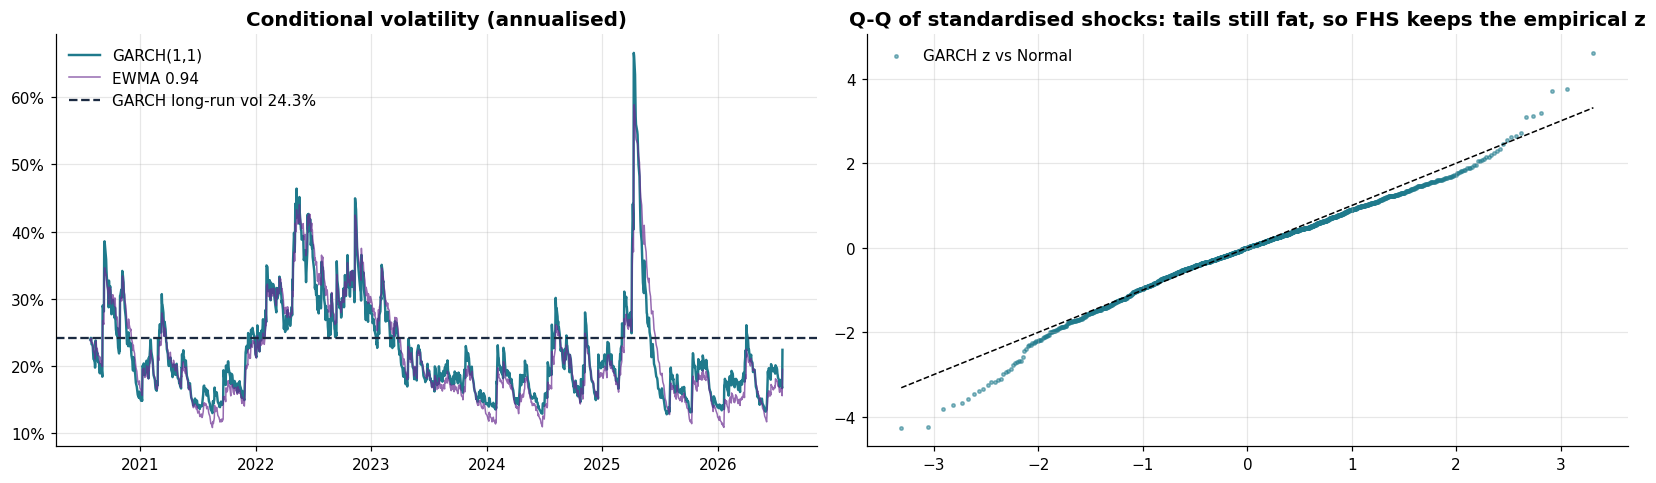

In [8]:
sig_full = garch_sigma(returns, P_FULL)
sig_ewma = np.sqrt(np.r_[(returns.iloc[:30] ** 2).mean(),
                         lfilter([1 - EWMA_LAMBDA], [1, -EWMA_LAMBDA], (returns ** 2).values[:-1],
                                 zi=[EWMA_LAMBDA * (returns.iloc[:30] ** 2).mean()])[0]])
sig_ewma = pd.Series(sig_ewma, index=returns.index)
zg = (returns - P_FULL['mu']) / sig_full
d = pd.DataFrame({'Raw returns': [returns.kurt(), *ljung_box(returns ** 2)],
                  'GARCH z': [zg.kurt(), *ljung_box(zg ** 2)],
                  'EWMA z (Task 5)': [(returns / sig_ewma).iloc[30:].kurt(), *ljung_box((returns / sig_ewma).iloc[30:] ** 2)]},
                 index=['Excess kurtosis', 'Ljung-Box Q(10) on squares', 'p-value'])
display(d.style.format('{:.3f}'))

fig, (a0, a1) = plt.subplots(1, 2, figsize=(15, 4.5))
a0.plot(sig_full * np.sqrt(TRADING_DAYS), color=COLORS['GARCH'], lw=1.6, label='GARCH(1,1)')
a0.plot(sig_ewma * np.sqrt(TRADING_DAYS), color=COLORS['EWMA'], lw=1, alpha=0.7, label='EWMA 0.94')
a0.axhline(P_FULL['long_run_vol_ann'], color=COLORS['ink'], ls='--', label=f'GARCH long-run vol {pct(P_FULL["long_run_vol_ann"], 1)}')
a0.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a0.legend(); a0.set_title('Conditional volatility (annualised)')
(osm, osr), _ = stats.probplot(zg, dist='norm')
a1.scatter(osm, osr, s=5, alpha=0.5, color=COLORS['GARCH'], label='GARCH z vs Normal')
lim = np.array([osm.min(), osm.max()]); a1.plot(lim, lim, 'k--', lw=1)
a1.set_title('Q-Q of standardised shocks: tails still fat, so FHS keeps the empirical z'); a1.legend()
plt.tight_layout(); plt.show()

## 4. Out-of-sample GARCH-FHS VaR (re-estimated every 21 days)
Every `REFIT_EVERY` days, starting once `MIN_EST` returns are available:
1. Fit GARCH on **all returns up to yesterday** only.
2. Filter σ and z through history with those parameters.
3. Forecast VaR and ES for the next 21 days, where each day uses σ_t and the trailing *W* shocks z up to t − 1.

Each refit warm-starts from the previous estimate, so it is fast and the parameters move smoothly.

In [9]:
def oos_garch_fhs(r, dist):
    n = len(r)
    sig_oos = pd.Series(np.nan, index=r.index)
    panel = {(w, c): pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES']) for w in WINDOWS for c in CONFIDENCES}
    hist, x0 = [], None
    for b in range(MIN_EST, n, REFIT_EVERY):
        P = fit_garch(r.iloc[:b], dist, x0)                    # data through day b-1 only
        x0 = P['_x']
        end = min(b + REFIT_EVERY, n)
        rr = r.iloc[:end]
        s = garch_sigma(rr, P)                                 # s_t uses r up to t-1
        zz = (rr / s).to_numpy()
        sig_oos.iloc[b:end] = s.iloc[b:end].values
        for (w, c), df in panel.items():
            lo = max(b, w)
            if lo >= end: continue
            sw = sliding_window_view(zz[lo - w:end - 1], w)     # rows -> days lo..end-1
            q = np.quantile(sw, 1 - c, axis=1); m = sw <= q[:, None]
            df.iloc[lo:end, 0] = -q * s.iloc[lo:end].values
            df.iloc[lo:end, 1] = -(sw * m).sum(1) / m.sum(1) * s.iloc[lo:end].values
        hist.append({'Estimated through': r.index[b - 1], **{k: P[k] for k in
                     ['mu', 'omega', 'alpha', 'beta', 'nu', 'persistence', 'long_run_vol_ann', 'half_life', 'converged']}})
    return panel, sig_oos, pd.DataFrame(hist).set_index('Estimated through')

t0 = time.time()
GARCH, sig_oos, PHIST = oos_garch_fhs(returns, DIST)
print(f'{len(PHIST)} out-of-sample refits in {time.time() - t0:.1f}s | all converged: {PHIST["converged"].all()}')
print(f'First GARCH forecast: {GARCH[(HEADLINE_W, HEADLINE_CL)]["VaR"].first_valid_index():%d %b %Y}')

# The shortcut used in many notebooks: one full-sample fit (look-ahead)
GARCH_IS = {(w, c): rolling_fhs(returns, sig_full, w, c) for w in WINDOWS for c in CONFIDENCES}

48 out-of-sample refits in 0.6s | all converged: True
First GARCH forecast: 21 Jul 2022


### 4a. Parameter stability
If the parameters drift a lot, a single full-sample fit misrepresents every sub-period. That is another reason to re-estimate.

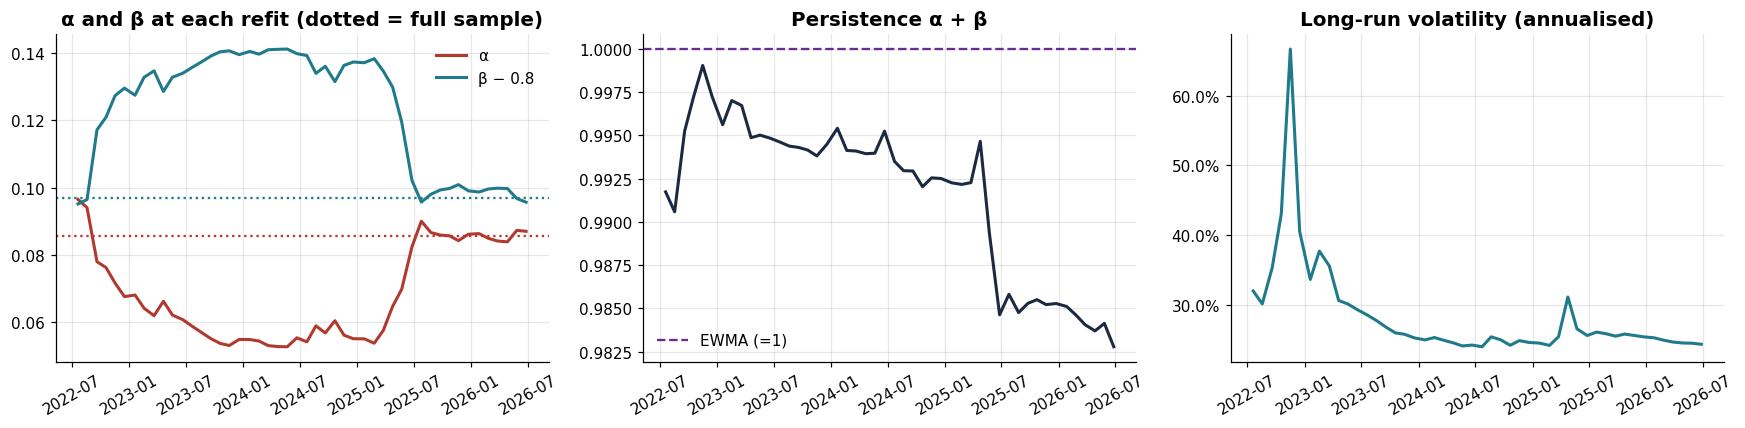

Persistence ranged 0.983-0.999; long-run vol 23.9%-66.7%.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(PHIST['alpha'], color=COLORS['loss'], lw=2, label='α'); axes[0].plot(PHIST['beta'] - 0.8, color=COLORS['GARCH'], lw=2, label='β − 0.8')
axes[0].axhline(P_FULL['alpha'], color=COLORS['loss'], ls=':'); axes[0].axhline(P_FULL['beta'] - 0.8, color=COLORS['GARCH'], ls=':')
axes[0].legend(); axes[0].set_title('α and β at each refit (dotted = full sample)')
axes[1].plot(PHIST['persistence'], color=COLORS['ink'], lw=2); axes[1].axhline(1, color=COLORS['EWMA'], ls='--', label='EWMA (=1)')
axes[1].legend(); axes[1].set_title('Persistence α + β')
axes[2].plot(PHIST['long_run_vol_ann'], color=COLORS['GARCH'], lw=2)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[2].set_title('Long-run volatility (annualised)')
for a in axes: a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
print(f'Persistence ranged {PHIST.persistence.min():.3f}-{PHIST.persistence.max():.3f}; '
      f'long-run vol {PHIST.long_run_vol_ann.min():.1%}-{PHIST.long_run_vol_ann.max():.1%}.')

### 4b. How much does look-ahead flatter the backtest?
We compare the honest out-of-sample model with the one-off full-sample fit on exactly the same dates.

In [11]:
oos_dates = GARCH[(HEADLINE_W, HEADLINE_CL)]['VaR'].dropna().index
la = []
for c in CONFIDENCES:
    for name, pnl_ in [('Out-of-sample (honest)', GARCH), ('Full-sample fit (look-ahead)', GARCH_IS)]:
        v = pnl_[(HEADLINE_W, c)]['VaR'].reindex(oos_dates)
        x = int((returns.reindex(oos_dates) < -v).sum())
        la.append({'Confidence': c, 'Version': name, 'Exceptions': x, 'Expected': len(v) * (1 - c),
                   'Kupiec p': kupiec(x, len(v), c)[1], 'Avg VaR': v.mean()})
pd.DataFrame(la).style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Kupiec p': '{:.3f}', 'Avg VaR': '{:.2%}'}).hide(axis='index')

Confidence,Version,Exceptions,Expected,Kupiec p,Avg VaR
95.0%,Out-of-sample (honest),47,50.3,0.629,2.12%
95.0%,Full-sample fit (look-ahead),47,50.3,0.629,2.14%
99.0%,Out-of-sample (honest),14,10.1,0.239,3.47%
99.0%,Full-sample fit (look-ahead),15,10.1,0.145,3.45%
99.5%,Out-of-sample (honest),10,5.0,0.050,3.93%
99.5%,Full-sample fit (look-ahead),9,5.0,0.110,3.92%


## 5. HS vs EWMA vs GARCH on identical dates
All three models come from the shared toolkit and are compared **only on dates where all three have a forecast**, so the comparison is fair. If Task 4 and 5 outputs exist in this session, they are checked against the recomputed values first.

In [12]:
HS   = {(w, c): rolling_hs(returns, w, c) for w in WINDOWS for c in CONFIDENCES}
EWMA = {(w, c): rolling_fhs(returns, sig_ewma, w, c) for w in WINDOWS for c in CONFIDENCES}
for f, P_ in [('HS_VaR.csv', HS), ('EWMA_VaR.csv', EWMA)]:
    if os.path.exists(f):
        m = f.split('_')[0]; col = f'{m}_VaR_{HEADLINE_W}d_{tag(HEADLINE_CL)}_Ret'
        prev = pd.read_csv(f, index_col=0, parse_dates=True)[col]
        assert np.allclose(prev.dropna(), P_[(HEADLINE_W, HEADLINE_CL)]['VaR'].dropna()), f'{f} mismatch'
        print(f'Consistency check passed: {f} reproduced exactly.')

MODELS = {'HS': HS, 'EWMA': EWMA, 'GARCH': GARCH}
score = []
for w in WINDOWS:
    common = oos_dates.intersection(HS[(w, 0.99)]['VaR'].dropna().index)
    t_ = pd.concat([backtest_table(m, P_, dates=common) for m, P_ in MODELS.items()])
    score.append(t_[t_.Window == w])
score = pd.concat(score, ignore_index=True)
style_bt(score[score.Confidence == HEADLINE_CL].sort_values(['Window', 'Model']).reset_index(drop=True))

Consistency check passed: HS_VaR.csv reproduced exactly.
Consistency check passed: EWMA_VaR.csv reproduced exactly.


Model,Window,Confidence,Start,Days,Exceptions,Expected,Rate,Kupiec p,Kupiec,Last 250d exc.,Basel zone,Avg VaR %,Avg ES %,VaR churn %
EWMA,250,99.0%,2022-07-21,1006,15,10.1,1.49%,0.145,PASS,4,GREEN,3.56%,4.16%,0.123%
GARCH,250,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,PASS,4,GREEN,3.47%,4.09%,0.129%
HS,250,99.0%,2022-07-21,1006,11,10.1,1.09%,0.769,PASS,2,GREEN,3.57%,4.16%,0.007%
EWMA,500,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,PASS,3,GREEN,3.51%,4.27%,0.117%
GARCH,500,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,PASS,3,GREEN,3.42%,4.18%,0.122%
HS,500,99.0%,2022-07-21,1006,10,10.1,0.99%,0.985,PASS,0,GREEN,3.95%,4.67%,0.004%
EWMA,750,99.0%,2023-07-20,756,15,7.6,1.98%,0.016,REJECT,5,YELLOW,3.12%,3.79%,0.106%
GARCH,750,99.0%,2023-07-20,756,14,7.6,1.85%,0.035,REJECT,4,GREEN,3.05%,3.74%,0.103%
HS,750,99.0%,2023-07-20,756,4,7.6,0.53%,0.153,PASS,1,GREEN,3.83%,4.67%,0.003%


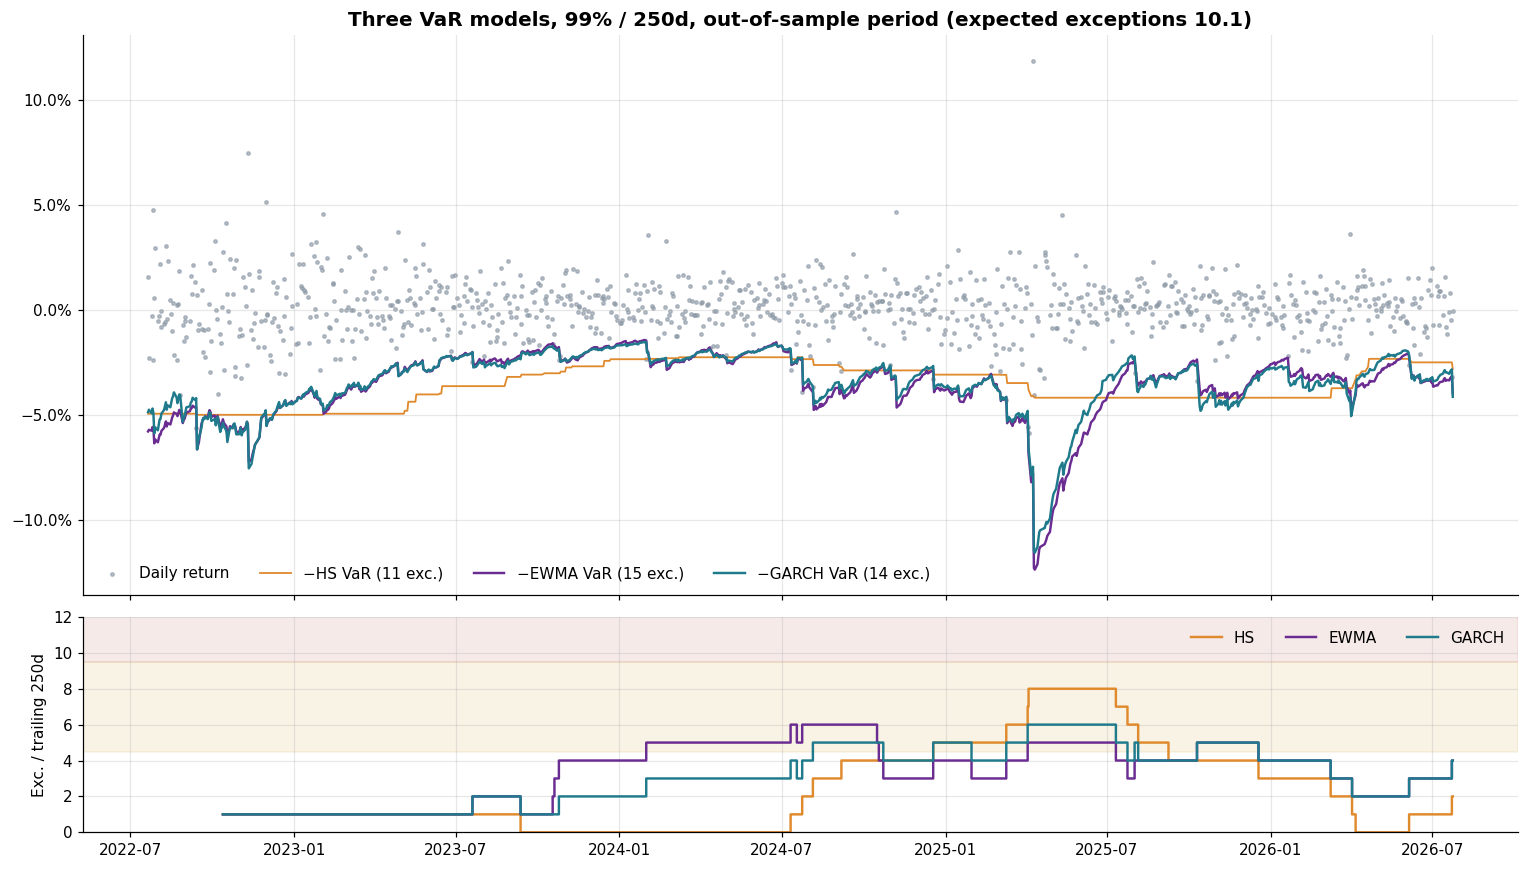

In [13]:
w, c = HEADLINE_W, HEADLINE_CL
d = oos_dates
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2.6, 1]})
ax.scatter(d, returns.reindex(d), s=5, color=COLORS['muted'], alpha=0.6, label='Daily return')
for m, P_ in MODELS.items():
    v = P_[(w, c)]['VaR'].reindex(d)
    x = int((returns.reindex(d) < -v).sum())
    ax.plot(-v, color=COLORS[m], lw=1.6 if m != 'HS' else 1.2, label=f'−{m} VaR ({x} exc.)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(ncol=4, loc='lower left')
ax.set_title(f'Three VaR models, {c:.0%} / {w}d, out-of-sample period (expected exceptions {len(d) * (1 - c):.1f})')
for m, P_ in MODELS.items():
    hit = (returns.reindex(d) < -P_[(w, c)]['VaR'].reindex(d)).astype(int)
    ax2.step(d, hit.rolling(250, min_periods=60).sum(), where='post', color=COLORS[m], lw=1.6, label=m)
ax2.axhspan(4.5, 9.5, color='#C78B00', alpha=0.1); ax2.axhspan(9.5, 30, color='#B03A2E', alpha=0.1)
ax2.set_ylim(0, max(12, ax2.get_ylim()[1])); ax2.set_ylabel('Exc. / trailing 250d'); ax2.legend(ncol=3)
plt.tight_layout(); plt.show()

## 6. Volatility term structure and 10-day VaR
GARCH forecasts volatility *paths*: from today's level, variance decays toward the long-run level at rate (α+β) per day:
$$\mathbb E[\sigma^2_{T+k}] = \bar\sigma^2 + (\alpha+\beta)^{k-1}(\sigma^2_{T+1} - \bar\sigma^2)$$
The 10-day variance is the sum of the daily forecasts. When today's volatility is below its long-run level, the √10 rule *understates* 10-day risk, and when it is above, √10 overstates it. EWMA can't make this distinction because it has no long-run anchor.

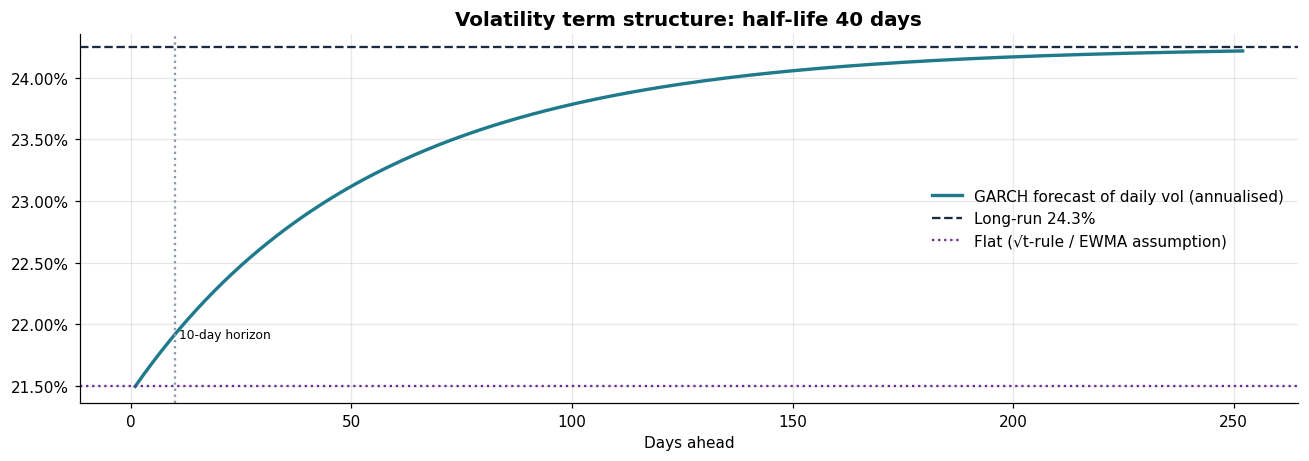

1-day 99% GARCH-FHS VaR : 4.18% = $188,722
10-day VaR, √10 rule          : 13.20% = $596,791
10-day VaR, GARCH term struct.: 13.34% = $602,821  (+1.0% vs √10)


In [14]:
P_now = fit_garch(returns, DIST, P_FULL['_x'])
h1 = garch_next(returns, P_now) ** 2
VL = P_now['omega'] / (1 - P_now['persistence'])
K = np.arange(1, 253)
hk = VL + P_now['persistence'] ** (K - 1) * (h1 - VL)
z_now = ((returns - P_now['mu']) / garch_sigma(returns, P_now)).iloc[-HEADLINE_W:]
qz = -np.quantile(z_now, 1 - HEADLINE_CL)
var1 = qz * np.sqrt(h1)
var10_garch = qz * np.sqrt(hk[:10].sum())
var10_sqrt = var1 * np.sqrt(10)

fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(K, np.sqrt(hk * TRADING_DAYS), color=COLORS['GARCH'], lw=2.2, label='GARCH forecast of daily vol (annualised)')
ax.axhline(np.sqrt(VL * TRADING_DAYS), color=COLORS['ink'], ls='--', label=f'Long-run {pct(np.sqrt(VL * TRADING_DAYS), 1)}')
ax.axhline(np.sqrt(h1 * TRADING_DAYS), color=COLORS['EWMA'], ls=':', label='Flat (√t-rule / EWMA assumption)')
ax.axvline(10, color=COLORS['muted'], ls=':'); ax.text(11, ax.get_ylim()[0] * 1.02 + 0.001, '10-day horizon', fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel('Days ahead'); ax.legend()
ax.set_title(f'Volatility term structure: half-life {P_now["half_life"]:.0f} days')
plt.tight_layout(); plt.show()
print(f'1-day {HEADLINE_CL:.0%} GARCH-FHS VaR : {pct(var1)} = {money(var1 * NAV)}')
print(f'10-day VaR, √10 rule          : {pct(var10_sqrt)} = {money(var10_sqrt * NAV)}')
print(f'10-day VaR, GARCH term struct.: {pct(var10_garch)} = {money(var10_garch * NAV)}  ({var10_garch / var10_sqrt - 1:+.1%} vs √10)')

## 7. Export for Tasks 7–9

In [15]:
g_out = export_model('GARCH', GARCH, 'GARCH_VaR.csv')
pd.DataFrame({'GARCH_Vol_Daily_OOS': sig_oos, 'GARCH_Vol_Daily_FullSample': sig_full,
              'Standardised_Return_FullSample': zg}).to_csv('GARCH_Volatility.csv')
pd.concat([ptab.T.assign(Spec='full-sample'), PHIST.assign(Spec='out-of-sample refit')]).to_csv('GARCH_Parameters.csv')

s_next = garch_next(returns, P_now)
zz = (returns - P_now['mu']) / garch_sigma(returns, P_now)
NEXT = {(w, c): tuple(s_next * np.array(var_es(zz.iloc[-w:], c))) for w in WINDOWS for c in CONFIDENCES}
bt_g = backtest_table('GARCH', GARCH)
update_summary(bt_g, NEXT)
summary = pd.read_csv(SUMMARY_FILE)
summary.query('Window == @HEADLINE_W and Confidence == @HEADLINE_CL')[
    ['Model', 'Start', 'Days', 'Exceptions', 'Expected', 'Kupiec p', 'Basel zone', 'Avg VaR %', 'Next-day VaR $', 'Next-day ES $']]

Saved GARCH_VaR.csv (1,506 rows x 48 cols) + data dictionary
VaR_Model_Summary.csv now holds models: ['EWMA', 'GARCH', 'HS']


,Model,Start,Days,Exceptions,Expected,Kupiec p,Basel zone,Avg VaR %,Next-day VaR $,Next-day ES $
1,HS,2021-07-23,1256,22,12.5600,0.0155,GREEN,0.0353,"126,797.4731","143,752.2396"
10,EWMA,2021-07-23,1256,18,12.5600,0.1474,GREEN,0.0373,"173,974.3428","208,774.7597"
19,GARCH,2022-07-21,1006,14,10.0600,0.2385,GREEN,0.0347,"188,721.9343","229,167.3729"


## 8. Executive summary

In [16]:
sc = score[(score.Window == HEADLINE_W) & (score.Confidence == HEADLINE_CL)].set_index('Model')
best = (sc['Exceptions'] - sc['Expected']).abs().idxmin()
nd = {m: summary.query('Model == @m and Window == @HEADLINE_W and Confidence == @HEADLINE_CL')['Next-day VaR $'].iloc[0]
      for m in summary.Model.unique() if m in MODELS}
display(Markdown(f"""
**Fitted dynamics ({DIST} likelihood, full sample).** α = {P_FULL['alpha']:.3f}, β = {P_FULL['beta']:.3f}, persistence **{P_FULL['persistence']:.3f}**
(half-life **{P_FULL['half_life']:.0f} days**, against EWMA's ~11), long-run volatility **{pct(P_FULL['long_run_vol_ann'], 1)}** a year.
Volatility shocks die out more slowly than EWMA assumes, but they do mean-revert.

**Out-of-sample discipline.** {len(PHIST)} monthly refits on past data only. Persistence moved between {PHIST.persistence.min():.3f} and {PHIST.persistence.max():.3f},
which supports re-estimating rather than relying on one full-sample fit.

**Scorecard ({HEADLINE_CL:.0%} / {HEADLINE_W}d, {int(sc.Days.iloc[0])} common days, {sc.Expected.iloc[0]:.1f} expected exceptions).**
""" + "\n".join(f"- **{m}**: {int(r.Exceptions)} exceptions, Kupiec p = {r['Kupiec p']:.3f}, average VaR {r['Avg VaR %']:.2%}, churn {r['VaR churn %']:.3%}/day, next-day VaR {money(nd.get(m, np.nan))}"
                for m, r in sc.iterrows()) + f"""

Closest to nominal coverage on this sample: **{best}**. The 10-day VaR from the GARCH term structure is {money(var10_garch * NAV)},
{var10_garch / var10_sqrt - 1:+.1%} against the √10 rule.

**Limitations and next steps.** GARCH(1,1) is **symmetric**: a −3% day and a +3% day raise volatility equally, although equity markets react more to losses
(the leverage effect). That points to an asymmetric model such as GJR-GARCH. Formal coverage *and* independence tests (Christoffersen, Basel) across every model in
`VaR_Model_Summary.csv` belong in **Task 8**.
"""))


**Fitted dynamics (t likelihood, full sample).** α = 0.086, β = 0.897, persistence **0.983**
(half-life **40 days**, against EWMA's ~11), long-run volatility **24.3%** a year.
Volatility shocks die out more slowly than EWMA assumes, but they do mean-revert.

**Out-of-sample discipline.** 48 monthly refits on past data only. Persistence moved between 0.983 and 0.999,
which supports re-estimating rather than relying on one full-sample fit.

**Scorecard (99% / 250d, 1006 common days, 10.1 expected exceptions).**
- **HS**: 11 exceptions, Kupiec p = 0.769, average VaR 3.57%, churn 0.007%/day, next-day VaR $126,797
- **EWMA**: 15 exceptions, Kupiec p = 0.145, average VaR 3.56%, churn 0.123%/day, next-day VaR $173,974
- **GARCH**: 14 exceptions, Kupiec p = 0.239, average VaR 3.47%, churn 0.129%/day, next-day VaR $188,722

Closest to nominal coverage on this sample: **HS**. The 10-day VaR from the GARCH term structure is $602,821,
+1.0% against the √10 rule.

**Limitations and next steps.** GARCH(1,1) is **symmetric**: a −3% day and a +3% day raise volatility equally, although equity markets react more to losses
(the leverage effect). That points to an asymmetric model such as GJR-GARCH. Formal coverage *and* independence tests (Christoffersen, Basel) across every model in
`VaR_Model_Summary.csv` belong in **Task 8**.


---
*Task 6 complete. All three VaR models now share one export schema and one summary file, ready for backtesting and model comparison.*

*Prepared by Arham Shah.*